# Sections 6 & 7 across 30 non-flaring holdout ARs — the stabilized 672 hr ensemble

`view_holdout_nonflaring30_sections67_672hr.ipynb` ran these measurements over the same 30 ARs
with the **original** 672 hr ensemble. Eight of that ensemble's ten members collapsed after their
peak (boot02 to IoU 0.0000, boot06 to 0.0572), so "best epoch" selected hard — epochs 0–3 of 5 —
and three members occasionally put a boundary 296–435 px from the ensemble. Its conclusions came
with an explicit caveat, recorded in `NOTES`:

> if this ensemble supersedes the old 672hr one, the sections 6/7 analysis (ICC, reliability, the
> 2.28x error/uncertainty ratio, "member diversity is lost") **has to be redone**. Some of those
> conclusions may be artifacts of members collapsing at different random epochs rather than real
> consequences of 4x the training data.

`672hr_stable` is that redo. Same ten bootstrap replicates, same LoRA geometry, same frozen
backbone, same 200-frame validation set — the *only* changes are 70 warmup steps, cosine decay to
`min_lr`, and `grad_clip_norm` 1.0. No member collapses: every run's last epoch is within 0.012
IoU of its own peak, selected-epoch IoU is 0.6274 ± 0.0252 against the old 0.5902 ± 0.0394, and
best-epoch selection barely selects at all (mean best-minus-final 0.0020).

So this notebook is a **paired A/B on optimizer stability**, over the same 30 ARs, measuring the
same two things:

| | old 672 hr, 30 ARs | HARP 11930, one frame |
|---|---|---|
| §6 error / uncertainty | 2.28 ± 1.31 | 2.07x |
| §6 uncertainty / error (px) | 13.97 / 24.96 | 5.25 / 10.88 |
| ICC (frame identity's share of the spread) | 0.192 | — |
| §7 bias ($\bar p$ − observed) | −0.0311, 23/30 under-confident | −0.0603 |
| Method A vs B correlation | $r$ = 0.053 | agreed to 1 % |

**The question is which of those five rows is a property of bootstrapping this model, and which
was a property of broken checkpoints.**

## Four things to hold on to before reading any number

**1. Uncertainty is not error, and this notebook never merges them.** Member scatter measures only
what the bootstrap can see. All ten members share one training distribution *and one seed*, so any
bias common to all of them is invisible to the spread. The ground-truth row exists to measure
exactly that gap.

**2. The truth masks are whole-disk.** `union_with_intersect` covers *every* AR in the frame, not
only the catalog's target HARP. "Non-flaring" therefore describes the target AR, not the frame: a
quiescent 15,000 Mkm² region can share its disk with something larger and livelier. §1 reports
each frame's own positive fraction rather than assuming the cohort is sparse.

**3. One Surya patch is 16 px, and that is the model's resolution floor.** Boundary agreement finer
than that is agreement about something the decoder cannot resolve. Read the *tail* and the
*across-frame spread*, not the median.

**4. The comparison against the old ensemble is paired, and it has to be.** The between-frame sd of
the ratio is 1.31 — far larger than any plausible shift between two training regimes — so comparing
two cohort means would resolve nothing. The 30 ARs are identical in both runs, so every comparison
below is per-AR, with Wilcoxon signed-rank on the differences. §1 verifies the pairing is real by
checking that the ground-truth positive fraction, a property of the masks alone, is bit-identical
between the two runs.

Read-only: no torch, no GPU. Everything comes from the cache `analyze_holdout_sections67.py` wrote.
Run from `downstream_examples/ar_segmentation/`.

## Setup

In [1]:
import json
import os
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from scipy import stats

if "." not in sys.path:
    sys.path.insert(0, ".")
import ensemble_viz as ev  # palette + raster helpers, shared with the other viewers
import false_color as fcolor  # SURYA_PATCH_PX

ev.apply_rcparams()

INFER_ROOT = "/efs/bathomas/ar_seg_bootstrap/672hr_stable_infer_holdout_nonflaring30"
# The original 672 hr ensemble over the *same* 30 ARs. Read per frame rather than quoted,
# so every old-vs-new number below is a paired difference instead of two headlines.
BASE_ROOT = "/efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_nonflaring30"
CATALOG = "./assets/surya-bench-ar-segmentation/holdout_ar_nonflaring_30_from_test.csv"
SCALERS_PATH = "./assets/scalers.yaml"
# The single-frame notebook's own section-8 cache, read for its published numbers rather
# than retyped. Its Brier/bias are not in that file (section 8 stored only the boundary
# attrs), so those two are the values the regression run of the analysis script
# reproduced exactly against the notebook's printed output. Both are *old*-regime
# figures: HARP 11930 has not been re-run under 672hr_stable.
REF_CACHE = "/efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_top3/20241001_1200/ensemble_mean.nc"
REF_BRIER, REF_BIAS = 0.1148, -0.0603

PATCH_PX = fcolor.SURYA_PATCH_PX
MIN_N = 1000          # reliability floor, as in the single-frame notebook
TRAIN_TRUE_FRAC = 0.00643   # training-era validation positive fraction
CHANNEL = "aia94"

frames = pd.read_csv(os.path.join(INFER_ROOT, "metrics_frame.csv"))
members = pd.read_csv(os.path.join(INFER_ROOT, "metrics_member_frame.csv"))
bins = pd.read_csv(os.path.join(INFER_ROOT, "calibration_bins.csv"))
dhist = pd.read_csv(os.path.join(INFER_ROOT, "distance_hist.csv"))
base_frames = pd.read_csv(os.path.join(BASE_ROOT, "metrics_frame.csv"))
base_members = pd.read_csv(os.path.join(BASE_ROOT, "metrics_member_frame.csv"))
base_bins = pd.read_csv(os.path.join(BASE_ROOT, "calibration_bins.csv"))
catalog = pd.read_csv(CATALOG)
scalers = yaml.safe_load(open(SCALERS_PATH))

MEMBERS = sorted(members.member.unique())
N = len(MEMBERS)
NF = len(frames)

with xr.open_dataset(REF_CACHE, engine="h5netcdf") as ds:
    REF = dict(ds.attrs)

print(f"{NF} frames x {N} members = {len(members)} member-frame rows")
print(f"baseline: {len(base_frames)} frames x "
      f"{base_members.member.nunique()} members = {len(base_members)} rows  (672hr)")
print(f"\nreference frame: {REF['frame']}  HARP {REF['harpnum']}  "
      f"UNC {float(REF['boundary_assd_px']):.2f} px  "
      f"ERR {float(REF['boundary_error_assd_px']):.2f} px  "
      f"ratio {float(REF['boundary_error_over_uncertainty']):.2f}x")

# Every downstream aggregate assumes a complete balanced design; a partial inference run
# would otherwise be averaged silently.
assert len(members) == NF * N, f"expected {NF * N} member-frame rows, got {len(members)}"
bad = frames[frames.mean_check_abs_diff > 1e-3]
print(f"\nframes failing the fp16 mean-is-a-mean check: {len(bad) if len(bad) else 'none'}")
empty = frames[frames.empty_boundary_members.fillna("").astype(str).str.strip().ne("")]
print(f"frames where some member predicted nothing:   {len(empty) if len(empty) else 'none'}")
print(f"epochs the members ran at: "
      f"{dict(members.groupby('member').epoch.first())}")

30 frames x 10 members = 300 member-frame rows
baseline: 30 frames x 10 members = 300 rows  (672hr)

reference frame: 20241001_1200  HARP 11930  UNC 5.25 px  ERR 10.88 px  ratio 2.07x

frames failing the fp16 mean-is-a-mean check: none
frames where some member predicted nothing:   none
epochs the members ran at: {'boot01': 5, 'boot02': 4, 'boot03': 5, 'boot04': 5, 'boot05': 4, 'boot06': 5, 'boot07': 5, 'boot08': 4, 'boot09': 4, 'boot10': 3}


## 1. The cohort

What was actually measured. The column that matters most for reading §2 is **truth AR fraction**:
it is the density confounder, and it is also the pairing check — the ground-truth mask is a
property of the frame alone, so it must come out *identical* to the old run. If it does not, the
two ensembles were not evaluated on the same thing and nothing below is paired.

In [2]:
cohort = frames.merge(
    catalog[["harpnum", "area_km2_million", "duration_days", "position", "n_flares",
             "max_goes_class", "n_euv_events", "noaa_regions"]],
    on="harpnum", how="left",
).sort_values("truth_frac", ascending=False)

tbl = cohort[["harpnum", "frame", "area_km2_million", "n_flares", "n_euv_events",
              "truth_frac", "truth_density_vs_train", "soft_iou",
              "boundary_assd_px", "boundary_error_assd_px",
              "boundary_error_over_uncertainty", "brier", "bias"]].copy()
tbl.columns = ["HARP", "frame", "area Mkm2", "flares", "EUV", "truth frac",
               "x train", "IoU", "UNC px", "ERR px", "ratio", "Brier", "bias"]
print(tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print(f"\ntruth AR fraction: mean {frames.truth_frac.mean():.5f}  "
      f"median {frames.truth_frac.median():.5f}  "
      f"[{frames.truth_frac.min():.5f}, {frames.truth_frac.max():.5f}]")
print(f"  = {frames.truth_density_vs_train.mean():.1f}x the training-era validation "
      f"fraction ({TRAIN_TRUE_FRAC:.5f}) on average")
print(f"  HARP 11930 for comparison: {float(REF['truth_positive_fraction']):.5f} "
      f"({float(REF['truth_positive_fraction']) / TRAIN_TRUE_FRAC:.1f}x)")
print(f"\n{int((cohort.n_flares == 0).sum())} of {NF} ARs are flare-free; "
      f"{int((cohort.n_flares > 0).sum())} have exactly one sub-C1.0 flare")
print(f"soft-mean IoU across the cohort: {frames.soft_iou.mean():.4f} +/- "
      f"{frames.soft_iou.std(ddof=1):.4f}  "
      f"[{frames.soft_iou.min():.4f}, {frames.soft_iou.max():.4f}]")

# --- the pairing check. One row per AR in both runs, same frame, same truth mask.
pair = frames.merge(base_frames, on="harpnum", suffixes=("", "_old"), validate="1:1")
assert len(pair) == NF, f"{len(pair)} of {NF} ARs matched the baseline run"
assert (pair.frame == pair.frame_old).all(), "same harpnum, different frame -- not paired"
same_truth = np.allclose(pair.truth_frac, pair.truth_frac_old, rtol=0, atol=1e-12)
print(f"\n--- pairing against the 672hr run ---")
print(f"  {len(pair)}/{NF} ARs matched on harpnum, all on the same frame")
print(f"  ground-truth positive fraction identical to the last bit: {same_truth}")
print(f"  max |difference| in truth_frac: "
      f"{np.abs(pair.truth_frac - pair.truth_frac_old).max():.3e}")
assert same_truth, "the two runs do not share ground truth; the comparison is not paired"

 HARP         frame  area Mkm2  flares  EUV  truth frac  x train    IoU  UNC px   ERR px  ratio  Brier    bias
11510 20240713_1700 16170.0000       0    2      0.0375   5.8311 0.7716 10.5936  53.8868 5.0867 0.1035 -0.0001
10434 20231127_0400 10889.0000       0    4      0.0344   5.3545 0.7617  7.0463  11.4763 1.6287 0.1030 -0.0332
11726 20240819_1900 11126.0000       0    6      0.0338   5.2623 0.8317  5.5684   6.7728 1.2163 0.0755 -0.0462
11555 20240719_1500 16004.0000       0    8      0.0330   5.1342 0.7767  5.2578   7.9828 1.5183 0.1095 -0.0101
11309 20240602_1400 11052.0000       0    4      0.0326   5.0657 0.8302  4.8069   8.0044 1.6652 0.0728 -0.0541
10515 20231220_1700 14163.0000       0    2      0.0292   4.5353 0.8136  7.6183  10.6937 1.4037 0.0855 -0.0161
11553 20240720_1800 18823.0000       0    2      0.0291   4.5208 0.7449  5.4849  16.0801 2.9317 0.1218  0.0496
10641 20240114_2200 13540.0000       0    1      0.0262   4.0671 0.6774 14.4281  25.2649 1.7511 0.1360  0.0006
1

## 2. §6 — how well located is the boundary, over 30 frames?

### What ASSD is

Every number in this section is an **average symmetric surface distance**, so it is worth being
exact about. For two binary masks $A$ and $B$, take each one's **boundary** $\partial A$ —
the inner one-pixel rind, i.e. the mask pixels having at least one of their eight neighbours
outside the mask (`analyze_holdout_sections67.boundary`, a full $3\times3$ erosion subtracted from
the mask) — and average the nearest-boundary distance in *both* directions:

$$\text{ASSD}(A, B) = \frac{1}{2}\left(
  \frac{1}{|\partial A|}\sum_{a \in \partial A} \min_{b \in \partial B} \lVert a - b \rVert
  \;+\;
  \frac{1}{|\partial B|}\sum_{b \in \partial B} \min_{a \in \partial A} \lVert b - a \rVert
\right)$$

Four consequences the numbers below cannot be read without:

- **The symmetry is not decoration.** A one-directional mean collapses whenever one mask is
  contained in the other — a prediction that finds half the AR and gets that half exactly right
  scores 0 in the direction from prediction to truth. Averaging both directions is what makes a
  *missed* region cost something, and it is why ERR stays large on frames whose IoU looks fine.
- **It is a mean, so one detached island moves it a long way.** That is deliberate: a boundary
  placed 300 px away is a detection failure and should dominate. The companion **HD95** (the 95th
  percentile) bounds that tail, and the pooled ECDF further down shows the whole distribution
  rather than either summary.
- **Euclidean distance in pixels on the native raster** — `scipy.ndimage.distance_transform_edt`
  over the 4096² north-up grid, no reprojection anywhere. 1 px = 0.6″, and 16 px = one Surya
  patch. The arcsec and km conversions use each frame's own WCS.
- **`median` and `HD95` in the table below are taken over the two directions *pooled*,** not as
  the median of the two means. They summarise the same set of distances a different way; they are
  not a different measurement.

ASSD is undefined when either boundary is empty — a member that predicted nothing has no boundary
to be a distance from — and is recorded as NaN. The setup cell confirms that never happened here.

### The three numbers

Three numbers carry the section:

- **UNC** — mean ASSD of the ten members' own $p_m = 0.5$ boundaries about the ensemble-mean
  boundary. What the bootstrap thinks it knows.
- **ERR** — the same measurement against the ground-truth mask. How wrong it is.
- **ratio** — ERR / UNC. **1.0 would mean the spread is an honest error bar.**

Reported as mean ± *between-frame* sd. Two ways to pool the ratio, and they answer different
questions: the mean of the 30 per-frame ratios weights every AR equally, while mean-ERR / mean-UNC
is the cohort-level ratio. Both are given because a few frames with tiny UNC can inflate the first.

In [3]:
def describe(series, fmt="{:.3f}"):
    v = pd.to_numeric(series, errors="coerce").dropna()
    return (f"{fmt.format(v.mean())} +/- {fmt.format(v.std(ddof=1))}   "
            f"median {fmt.format(v.median())}   "
            f"[{fmt.format(v.min())}, {fmt.format(v.max())}]")


print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("UNCERTAINTY  ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("  between-member sd (px)", "boundary_assd_sd_px", "{:.2f}"),
    ("  median (px)", "boundary_median_px", "{:.2f}"),
    ("  mean HD95 (px)", "boundary_hd95_px", "{:.1f}"),
    ("ERROR  ASSD (px)", "boundary_error_assd_px", "{:.2f}"),
    ("  median (px)", "boundary_error_median_px", "{:.2f}"),
    ("  HD95 (px)", "boundary_error_hd95_px", "{:.1f}"),
    ("ERROR / UNCERTAINTY", "boundary_error_over_uncertainty", "{:.2f}"),
    ("sigma_p on the boundary", "boundary_sigma_prob", "{:.4f}"),
]:
    print(f"{label:<34}{describe(frames[col], fmt)}")

UNC = frames.boundary_assd_px.mean()
ERR = frames.boundary_error_assd_px.mean()
ratio_mean = frames.boundary_error_over_uncertainty.mean()
ratio_pooled = ERR / UNC
ref_ratio = float(REF["boundary_error_over_uncertainty"])

print(f"\n--- the headline ---")
print(f"  mean of the {NF} per-frame ratios : {ratio_mean:.2f}x  "
      f"(sd {frames.boundary_error_over_uncertainty.std(ddof=1):.2f})")
print(f"  cohort ratio, mean ERR / mean UNC : {ratio_pooled:.2f}x")
print(f"  old 672hr ensemble, same 30 ARs   : "
      f"{base_frames.boundary_error_over_uncertainty.mean():.2f}x  "
      f"(sd {base_frames.boundary_error_over_uncertainty.std(ddof=1):.2f})")
print(f"  HARP 11930, single frame          : {ref_ratio:.2f}x")
n_over = int((frames.boundary_error_over_uncertainty > 1).sum())
print(f"\n  frames where error exceeds uncertainty: {n_over}/{NF}")
print(f"  frames where it exceeds 2x:             "
      f"{int((frames.boundary_error_over_uncertainty > 2).sum())}/{NF}")
print(f"\n  for scale, one Surya patch is {PATCH_PX} px "
      f"({PATCH_PX * frames.arcsec_per_px.mean():.1f} arcsec, "
      f"{PATCH_PX * frames.km_per_px.mean():,.0f} km at disk centre)")
print(f"  mean UNC in physical units: {UNC * frames.arcsec_per_px.mean():.2f} arcsec = "
      f"{(frames.boundary_assd_px * frames.km_per_px).mean():,.0f} km")
print(f"  mean ERR in physical units: {ERR * frames.arcsec_per_px.mean():.2f} arcsec = "
      f"{(frames.boundary_error_assd_px * frames.km_per_px).mean():,.0f} km")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
UNCERTAINTY  ASSD (px)            9.73 +/- 5.54   median 8.15   [2.51, 28.10]
  between-member sd (px)          6.87 +/- 6.89   median 4.47   [0.67, 36.57]
  median (px)                     1.11 +/- 0.35   median 1.00   [1.00, 2.83]
  mean HD95 (px)                  64.2 +/- 61.7   median 40.2   [12.4, 318.4]
ERROR  ASSD (px)                  24.32 +/- 20.37   median 16.87   [5.58, 100.06]
  median (px)                     3.76 +/- 2.36   median 3.00   [2.24, 14.32]
  HD95 (px)                       166.6 +/- 204.7   median 101.8   [23.3, 1010.7]
ERROR / UNCERTAINTY               2.55 +/- 1.39   median 1.95   [0.76, 5.44]
sigma_p on the boundary           0.2225 +/- 0.0288   median 0.2236   [0.1703, 0.2986]

--- the headline ---
  mean of the 30 per-frame ratios : 2.55x  (sd 1.39)
  cohort ratio, mean ERR / mean UNC : 2.50x
  old 672hr

### Did the stabilization change any of it? The paired test

The same 30 ARs under both ensembles, differenced per AR. Wilcoxon signed-rank rather than a
paired $t$: $n = 30$ and the ratio is long-tailed in both runs, so a mean difference is not the
statistic to test.

Four quantities, and they can move independently — that is the point of separating them:

- **UNC** should *rise* if the old ensemble's tightness was partly members agreeing because they
  were all overfit at their own idiosyncratic best epoch.
- **ERR** should *fall* if removing the collapsed members improved the ensemble mean.
- **ratio** is the headline, and it falls only if ERR improves faster than UNC grows.
- **soft IoU** is the sanity check: the stable members score +0.037 higher on validation, so if
  holdout IoU does not move, the holdout is not seeing the training-set gain.

In [4]:
def paired(col, fmt="{:.3f}", higher_is_better=None):
    """One row of the paired table: new, old, difference, Wilcoxon on the difference."""
    new = pd.to_numeric(pair[col], errors="coerce")
    old = pd.to_numeric(pair[f"{col}_old"], errors="coerce")
    d = (new - old).dropna()
    stat, p = stats.wilcoxon(d)
    n_up = int((d > 0).sum())
    arrow = ""
    if higher_is_better is not None and p < 0.05:
        better = (d.median() > 0) == higher_is_better
        arrow = "  better" if better else "  WORSE"
    return (f"{fmt.format(new.mean()):>10}{fmt.format(old.mean()):>10}"
            f"{fmt.format(d.mean()):>11}{fmt.format(d.median()):>11}"
            f"{n_up:>6}/{len(d)}{p:>10.2e}{arrow}")


print(f"{'':<30}{'stable':>10}{'672hr':>10}{'mean d':>11}{'median d':>11}"
      f"{'n up':>8}{'Wilcoxon':>12}")
print("-" * 98)
for label, col, fmt, hib in [
    ("UNCERTAINTY ASSD (px)", "boundary_assd_px", "{:.2f}", False),
    ("ERROR ASSD (px)", "boundary_error_assd_px", "{:.2f}", False),
    ("ERROR / UNCERTAINTY", "boundary_error_over_uncertainty", "{:.2f}", False),
    ("member HD95 (px)", "boundary_hd95_px", "{:.1f}", False),
    ("error HD95 (px)", "boundary_error_hd95_px", "{:.1f}", False),
    ("sigma_p on the boundary", "boundary_sigma_prob", "{:.4f}", None),
    ("soft-mean IoU", "soft_iou", "{:.4f}", True),
    ("soft precision", "soft_precision", "{:.4f}", True),
    ("soft recall", "soft_recall", "{:.4f}", True),
    ("member IoU sd", "member_iou_sd", "{:.4f}", None),
]:
    print(f"{label:<30}{paired(col, fmt, hib)}")

d_ratio = pair.boundary_error_over_uncertainty - pair.boundary_error_over_uncertainty_old
print(f"\n  ARs whose ratio improved (fell): {int((d_ratio < 0).sum())}/{NF}")
print(f"  ARs still above 1.0 under both: "
      f"{int(((pair.boundary_error_over_uncertainty > 1) & (pair.boundary_error_over_uncertainty_old > 1)).sum())}/{NF}")
print(f"  ARs that crossed below 1.0: "
      f"{int(((pair.boundary_error_over_uncertainty <= 1) & (pair.boundary_error_over_uncertainty_old > 1)).sum())}")
print(f"\n  the old run's three detection-failure members put boundaries 296-435 px from the")
print(f"  ensemble; worst single member-frame ASSD here: {members.assd_px.max():.1f} px "
      f"(old run: {base_members.assd_px.max():.1f} px)")
print(f"  member-frames above 100 px: {int((members.assd_px > 100).sum())}/{len(members)} "
      f"(old run: {int((base_members.assd_px > 100).sum())}/{len(base_members)})")

                                  stable     672hr     mean d   median d    n up    Wilcoxon
--------------------------------------------------------------------------------------------------
UNCERTAINTY ASSD (px)               9.73     13.97      -4.24      -0.40     9/30  1.00e-01
ERROR ASSD (px)                    24.32     24.96      -0.65      -0.90     9/30  8.03e-02
ERROR / UNCERTAINTY                 2.55      2.28       0.26      -0.01    15/30  5.84e-01
member HD95 (px)                    64.2      86.8      -22.6       -1.2    13/30  4.90e-01
error HD95 (px)                    166.6     166.5        0.1       -0.7    15/30  8.24e-01
sigma_p on the boundary           0.2225    0.2376    -0.0151    -0.0167     5/30  4.41e-05
soft-mean IoU                     0.7407    0.7115     0.0292     0.0292    29/30  2.55e-07  better
soft precision                    0.8707    0.8772    -0.0065    -0.0041    13/30  6.99e-02
soft recall                       0.8305    0.7904     0.0401   

### The paired comparison as a chart

**Left — one line per AR**, from its old ratio to its new one. A slope chart, because the quantity
is *change between two conditions per entity* and the pairing is the whole point; a pair of
box plots would discard exactly the information the Wilcoxon test uses. Lines are coloured by
direction (blue down, orange up) — polarity, two hues about a neutral — and the heavy ink line is
the cohort mean.

**Right — absolute scale.** Old against new for both quantities, with the $y = x$ diagonal.
Everything below the diagonal got smaller. Both axes are pixels on one shared scale, so the two
series can share a panel without inventing a second y-axis.

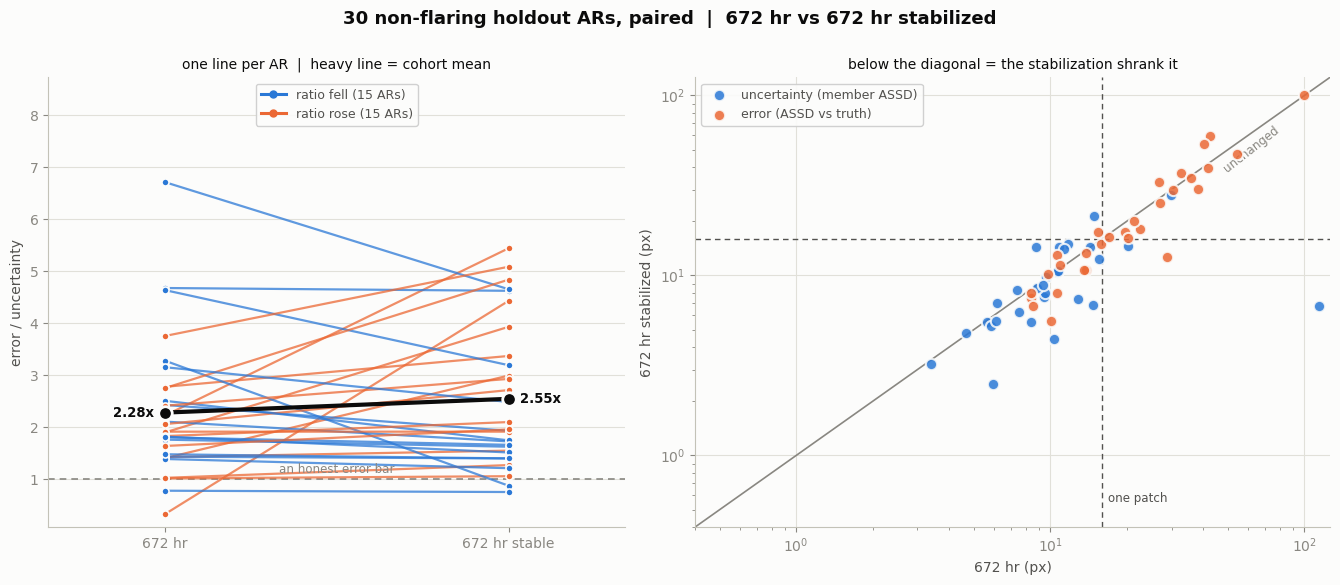

In [5]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13.5, 5.8),
                               gridspec_kw={"width_ratios": [1, 1.1]})
fig.suptitle(f"{NF} non-flaring holdout ARs, paired  |  672 hr vs 672 hr stabilized",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

# ---- left: slope chart of the per-AR error/uncertainty ratio
old_r = pair.boundary_error_over_uncertainty_old.values
new_r = pair.boundary_error_over_uncertainty.values
for o, nw in zip(old_r, new_r):
    down = nw < o
    axl.plot([0, 1], [o, nw], color=ev.SERIES_1 if down else ev.SERIES_2,
             lw=1.6, alpha=0.75, zorder=3,
             solid_capstyle="round")
    axl.scatter([0, 1], [o, nw], s=26,
                color=ev.SERIES_1 if down else ev.SERIES_2, zorder=4,
                edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.2)
axl.plot([0, 1], [old_r.mean(), new_r.mean()], color=ev.INK, lw=3.0, zorder=5,
         solid_capstyle="round")
axl.scatter([0, 1], [old_r.mean(), new_r.mean()], s=95, color=ev.INK, zorder=6,
            edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
axl.annotate(f"{old_r.mean():.2f}x", (0, old_r.mean()), xytext=(-8, 0),
             textcoords="offset points", ha="right", va="center", fontsize=9.5,
             color=ev.INK, fontweight="bold")
axl.annotate(f"{new_r.mean():.2f}x", (1, new_r.mean()), xytext=(8, 0),
             textcoords="offset points", ha="left", va="center", fontsize=9.5,
             color=ev.INK, fontweight="bold")
axl.axhline(1.0, color=ev.MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
axl.annotate("an honest error bar", (0.5, 1.0), xytext=(0, 5),
             textcoords="offset points", ha="center", fontsize=8.5, color=ev.MUTED)
axl.set_xlim(-0.34, 1.34)
# Headroom so the legend sits over empty space rather than over the lines, and a floor
# below the smallest ratio in either run so no endpoint is clipped to the axis.
both = np.concatenate([old_r, new_r])
axl.set_ylim(both.min() - 0.25, both.max() * 1.30)
axl.set_xticks([0, 1])
axl.set_xticklabels(["672 hr", "672 hr stable"])
axl.set_ylabel("error / uncertainty")
axl.set_title("one line per AR  |  heavy line = cohort mean", fontsize=10, color=ev.INK)
axl.legend(handles=[
    plt.Line2D([], [], color=ev.SERIES_1, lw=2.2, marker="o", ms=5,
               label=f"ratio fell ({int((new_r < old_r).sum())} ARs)"),
    plt.Line2D([], [], color=ev.SERIES_2, lw=2.2, marker="o", ms=5,
               label=f"ratio rose ({int((new_r >= old_r).sum())} ARs)")],
    loc="upper center", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ev.recessive(axl)
axl.grid(axis="x", visible=False)

# ---- right: absolute scale, old against new, both quantities on one px axis
lim = max(pair[["boundary_assd_px", "boundary_assd_px_old",
                "boundary_error_assd_px", "boundary_error_assd_px_old"]].max()) * 1.1
axr.plot([0.4, lim], [0.4, lim], color=ev.MUTED, lw=1.2, zorder=1)
axr.annotate("unchanged", (lim * 0.5, lim * 0.5), xytext=(0, -15),
             textcoords="offset points", ha="center", fontsize=8.5, color=ev.MUTED,
             rotation=38, rotation_mode="anchor")
for col, color, label in [
    ("boundary_assd_px", ev.SERIES_1, "uncertainty (member ASSD)"),
    ("boundary_error_assd_px", ev.SERIES_2, "error (ASSD vs truth)"),
]:
    axr.scatter(pair[f"{col}_old"], pair[col], s=66, color=color, alpha=0.85, zorder=3,
                edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5, label=label)
axr.axvline(PATCH_PX, color=ev.INK_2, lw=1.0, ls=(0, (4, 3)), zorder=2)
axr.axhline(PATCH_PX, color=ev.INK_2, lw=1.0, ls=(0, (4, 3)), zorder=2)
axr.annotate("one patch", (PATCH_PX, 0.55), xytext=(4, 0), textcoords="offset points",
             fontsize=8.5, color=ev.INK_2)
axr.set_xscale("log")
axr.set_yscale("log")
axr.set_xlim(0.4, lim)
axr.set_ylim(0.4, lim)
axr.set_xlabel("672 hr (px)")
axr.set_ylabel("672 hr stabilized (px)")
axr.set_title("below the diagonal = the stabilization shrank it", fontsize=10, color=ev.INK)
axr.legend(loc="upper left", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ev.recessive(axr)
axr.grid(axis="x", visible=True, which="major")

plt.tight_layout()
plt.show()

### Is any one member reliably tighter than the others?

On HARP 11930 boot07 was the tightest member (ASSD 2.84 px) and boot08 the loosest (7.96 px). With
one frame there is no way to tell a real property of a checkpoint from the luck of a single draw.
Thirty frames can.

**Kendall's $W$** is the concordance of the 30 per-frame rankings: 1.0 means every frame orders the
members identically, 0 means the orderings are unrelated. A high $W$ says member identity is a real
and transferable property; a low one says per-frame ranking is noise.

The `ASSD old` column pairs each member against **its own replicate** in the earlier run — boot07
here and boot07 there trained on the same 672 bootstrap samples and differ only in the optimizer
schedule — so that column is a within-replicate comparison, not a relabelling.

In [6]:
per_member = members.groupby("member").agg(
    assd_mean=("assd_px", "mean"), assd_sd=("assd_px", "std"),
    assd_min=("assd_px", "min"), assd_max=("assd_px", "max"),
    median_px=("median_px", "mean"), hd95=("hd95_px", "mean"),
    iou=("iou", "mean"), val_iou=("val_iou", "first"), epoch=("epoch", "first"),
).sort_values("assd_mean")
base_per_member = base_members.groupby("member").agg(
    assd_old=("assd_px", "mean"), iou_old=("iou", "mean"),
    val_iou_old=("val_iou", "first"), epoch_old=("epoch", "first"),
)
per_member = per_member.join(base_per_member)

wide = members.pivot(index="frame", columns="member", values="assd_px")[list(per_member.index)]
ranks = wide.rank(axis=1)                      # 1 = tightest, within each frame
per_member["mean_rank"] = ranks.mean()
per_member["rank_sd"] = ranks.std(ddof=1)

out = per_member[["epoch", "val_iou", "assd_mean", "assd_sd", "assd_min", "assd_max",
                  "median_px", "hd95", "iou", "mean_rank", "rank_sd",
                  "epoch_old", "val_iou_old", "assd_old", "iou_old"]].copy()
out.columns = ["ep", "val IoU", "ASSD px", "sd", "min", "max", "median", "HD95",
               "IoU", "rank", "rank sd", "ep old", "val IoU old", "ASSD old", "IoU old"]
print(out.to_string(float_format=lambda x: f"{x:.3f}"))

chi2, p_fried = stats.friedmanchisquare(*[wide[m].values for m in wide.columns])
W = chi2 / (NF * (N - 1))                      # Kendall's W from the Friedman statistic
base_wide = base_members.pivot(index="frame", columns="member", values="assd_px")
chi2_o, p_o = stats.friedmanchisquare(*[base_wide[m].values for m in base_wide.columns])
W_old = chi2_o / (len(base_wide) * (base_wide.shape[1] - 1))
print(f"\nKendall's W over the {NF} per-frame rankings: {W:.3f}  "
      f"(Friedman chi2 {chi2:.1f}, p {p_fried:.2e})")
print(f"  the old 672hr ensemble, same frames:        {W_old:.3f}  (p {p_o:.2e})")
print("  W near 1 -> member identity transfers across frames; "
      "near 0 -> per-frame ranking is noise")

tightest, loosest = per_member.index[0], per_member.index[-1]
print(f"\ntightest overall: {tightest} ({per_member.assd_mean.iloc[0]:.2f} px), "
      f"loosest: {loosest} ({per_member.assd_mean.iloc[-1]:.2f} px)")
print(f"  how often is {tightest} the tightest member of its frame? "
      f"{int((ranks[tightest] == 1).sum())}/{NF}")
print(f"  how often is {loosest} the loosest?                  "
      f"{int((ranks[loosest] == N).sum())}/{NF}")
print(f"  on HARP 11930 the tightest was boot07 (2.84 px), the loosest boot08 (7.96 px)")
print(f"\nper-member ASSD, paired against the same replicate in the old run:")
rho_m, p_m = stats.spearmanr(per_member.assd_mean, per_member.assd_old)
print(f"  Spearman rho {rho_m:+.3f} (p {p_m:.3f}) -- does a loose replicate stay loose "
      f"when retrained?")
w_m = stats.wilcoxon(per_member.assd_mean - per_member.assd_old)
print(f"  Wilcoxon on the {N} per-member differences: p {w_m.pvalue:.3f}  "
      f"(mean {(per_member.assd_mean - per_member.assd_old).mean():+.2f} px)")

        ep  val IoU  ASSD px     sd   min    max  median    HD95   IoU  rank  rank sd  ep old  val IoU old  ASSD old  IoU old
member                                                                                                                       
boot07   5    0.660    6.096  4.154 1.410 23.268   1.116  30.087 0.733 4.167    2.743       3        0.610     5.644    0.700
boot05   4    0.657    6.998  5.248 1.613 29.400   1.094  39.883 0.722 4.767    2.635       2        0.634     8.344    0.692
boot03   5    0.657    7.693  7.377 1.637 31.453   1.061  55.540 0.725 4.067    2.864       2        0.617     5.854    0.680
boot10   3    0.621    8.500  5.474 2.135 20.219   1.130  55.576 0.709 5.933    2.392       2        0.570    10.830    0.689
boot04   5    0.645    9.565 12.163 2.088 65.800   1.094  57.425 0.722 4.800    3.044       1        0.631     6.075    0.695
boot08   4    0.597    9.661  8.369 1.615 36.081   1.189  59.964 0.712 5.800    3.022       0        0.518    31.237  

### Variance decomposition — is the member spread an error bar, or is the frame?

A one-way random-effects split of the 300 per-member ASSD values, with frame as the grouping
factor:

$$\sigma^2_{\text{total}} = \sigma^2_{\text{between frames}} + \sigma^2_{\text{within frame (members)}}$$

The **intraclass correlation** $\text{ICC} = \sigma^2_b / (\sigma^2_b + \sigma^2_w)$ is the
fraction of all variation attributable to *which AR you are looking at*.

This is the statistic that decides how to read a bootstrap error bar. A high ICC means the member
spread quoted on any single frame is mostly telling you about that frame, and the quantity does not
transfer. A low ICC means members genuinely disagree by a frame-independent amount.

The old run's ICC was **0.192** — but `NOTES` flagged that as driven by three collapsed members'
heavy tail rather than by uniform scatter. With no collapsed members, a *higher* ICC here would
confirm that reading: remove the outlier members and frame identity recovers its share.

In [7]:
def icc_oneway(w):
    """(grand mean, MS_between, MS_within, sigma_b, sigma_w, ICC) for frames x members."""
    k_, m_ = w.shape
    grand = w.values.mean()
    frame_means = w.mean(axis=1)
    ms_between = m_ * ((frame_means - grand) ** 2).sum() / (k_ - 1)
    ms_within = ((w.values - frame_means.values[:, None]) ** 2).sum() / (k_ * (m_ - 1))
    var_between = max((ms_between - ms_within) / m_, 0.0)   # a negative estimate means 0
    return (grand, ms_between, ms_within, np.sqrt(var_between), np.sqrt(ms_within),
            var_between / (var_between + ms_within))


grand, ms_between, ms_within, sig_b, sig_w, icc = icc_oneway(wide)
_, _, _, sig_b_o, sig_w_o, icc_o = icc_oneway(base_wide)

print(f"one-way random effects on the {NF * N} member-frame ASSD values")
print(f"  grand mean                        {grand:.3f} px")
print(f"  MS between frames                 {ms_between:.3f}")
print(f"  MS within frames (members)        {ms_within:.3f}")
print(f"\n  sigma_between (frame identity)    {sig_b:.3f} px   "
      f"({100 * icc:.0f} % of variance)")
print(f"  sigma_within  (member spread)     {sig_w:.3f} px   "
      f"({100 * (1 - icc):.0f} % of variance)")
print(f"  ICC                               {icc:.3f}")
print(f"\n  the old 672hr ensemble, same frames:")
print(f"  sigma_between {sig_b_o:.3f} px   sigma_within {sig_w_o:.3f} px   "
      f"ICC {icc_o:.3f}")
print(f"\n  between-frame sd of the frame means: {wide.mean(axis=1).std(ddof=1):.3f} px")
print(f"  mean within-frame sd across frames:  {wide.std(axis=1, ddof=1).mean():.3f} px")

one-way random effects on the 300 member-frame ASSD values
  grand mean                        9.731 px
  MS between frames                 306.917
  MS within frames (members)        93.158

  sigma_between (frame identity)    4.623 px   (19 % of variance)
  sigma_within  (member spread)     9.652 px   (81 % of variance)
  ICC                               0.187

  the old 672hr ensemble, same frames:
  sigma_between 16.514 px   sigma_within 33.905 px   ICC 0.192

  between-frame sd of the frame means: 5.540 px
  mean within-frame sd across frames:  6.873 px


### Method A vs Method B

$\sigma_r = \sigma_p / |\nabla \bar p|$ (A, the linearized level-set displacement) and the
empirical ASSD (B, the headline) rest on different assumptions, so agreement between them would be
the check that either is meaningful. On HARP 11930 they agreed to 1 % on the mean; **across the old
run's 30 frames they did not** ($r$ = 0.053), and the notebook concluded A is a *local*
linearization that structurally cannot see a detached island or a whole region the ensemble missed
— exactly what inflates B.

That diagnosis makes a prediction worth testing here: if A fails because of detection failures,
then an ensemble with no collapsed members should bring the two closer. The two assumptions A rests
on are measured per frame rather than asserted:

- **within-patch range** — if $\bar p$ were flat inside a patch, the raw gradient would be
  meaningless and the field would have to be smoothed first.
- **patch-seam bias** — the gradient is steeper on patch seams, which makes A run optimistic where
  the boundary sits on one.

In [8]:
cmp = frames[["frame", "boundary_assd_px", "sigma_r_mean_px", "sigma_r_median_px",
              "sigma_r_p90_px", "within_patch_range", "seam_bias_ratio"]].copy()
cmp["rel_diff_pct"] = 100 * (cmp.sigma_r_mean_px - cmp.boundary_assd_px) / cmp.boundary_assd_px

print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("Method B  ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("Method A  sigma_r mean (px)", "sigma_r_mean_px", "{:.2f}"),
    ("Method A  sigma_r median (px)", "sigma_r_median_px", "{:.2f}"),
    ("Method A  sigma_r p90 (px)", "sigma_r_p90_px", "{:.1f}"),
    ("A - B, as % of B", "rel_diff_pct", "{:+.1f}"),
    ("within-patch range of p-bar", "within_patch_range", "{:.3f}"),
    ("patch-seam gradient bias (x)", "seam_bias_ratio", "{:.2f}"),
]:
    print(f"{label:<34}{describe(cmp[col], fmt)}")

r, p_r = stats.pearsonr(cmp.boundary_assd_px, cmp.sigma_r_mean_px)
r_o, p_ro = stats.pearsonr(base_frames.boundary_assd_px, base_frames.sigma_r_mean_px)
print(f"\nA vs B across the {NF} frames: r = {r:.3f} (p {p_r:.2e})")
print(f"  the old 672hr ensemble, same frames: r = {r_o:.3f} (p {p_ro:.2e})")
print(f"  frames where the two agree to within 20 %: "
      f"{int((cmp.rel_diff_pct.abs() <= 20).sum())}/{NF}  "
      f"(old run: {int((100 * (base_frames.sigma_r_mean_px - base_frames.boundary_assd_px) / base_frames.boundary_assd_px).abs().le(20).sum())}/{NF})")
print(f"  on HARP 11930 they agreed to 1 % on the mean")
print(f"\nis p-bar flat inside a patch anywhere? "
      f"min within-patch range {cmp.within_patch_range.min():.3f} "
      f"-> {'no, the raw gradient is a real slope everywhere' if cmp.within_patch_range.min() > 0.1 else 'YES on some frame -- check it'}")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Method B  ASSD (px)               9.73 +/- 5.54   median 8.15   [2.51, 28.10]
Method A  sigma_r mean (px)       5.96 +/- 2.24   median 5.49   [2.91, 10.80]
Method A  sigma_r median (px)     2.58 +/- 0.95   median 2.35   [1.57, 6.08]
Method A  sigma_r p90 (px)        13.1 +/- 5.5   median 11.9   [6.0, 27.2]
A - B, as % of B                  -27.2 +/- +29.7   median -29.5   [-83.1, +35.8]
within-patch range of p-bar       0.692 +/- 0.042   median 0.698   [0.565, 0.767]
patch-seam gradient bias (x)      1.33 +/- 0.05   median 1.34   [1.23, 1.40]

A vs B across the 30 frames: r = 0.386 (p 3.53e-02)
  the old 672hr ensemble, same frames: r = 0.053 (p 7.81e-01)
  frames where the two agree to within 20 %: 7/30  (old run: 4/30)
  on HARP 11930 they agreed to 1 % on the mean

is p-bar flat inside a patch anywhere? min within-patch range 0.565 

### Uncertainty and error, per member and per AR

Members in blue with **between-frame** error bars, sorted by mean ASSD; each AR's own ERR against
truth in orange on the right-hand panel. The reference line is one Surya patch — the resolution
floor, below which "agreement" is agreement about something the decoder cannot represent.

A dot plot, not a lollipop: position encodes the value and nothing encodes length, so the axis is
free to zoom to the data rather than spending itself on an empty 0–2 px range.

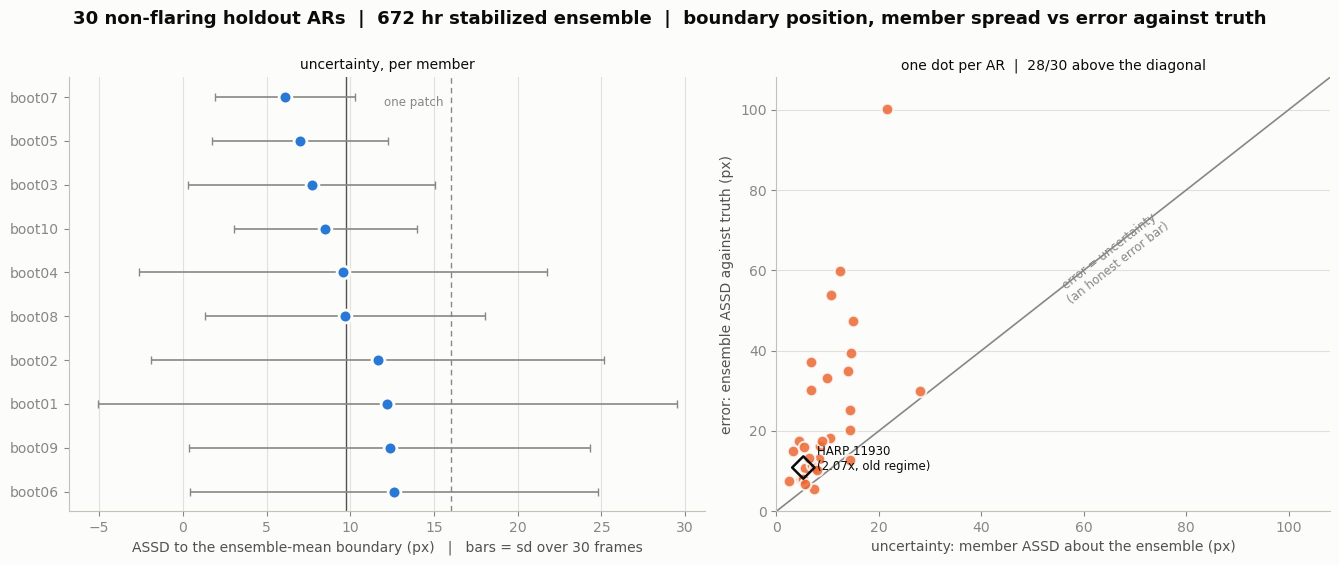

In [9]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13.5, 5.6),
                               gridspec_kw={"width_ratios": [1.15, 1]})
fig.suptitle(f"{NF} non-flaring holdout ARs  |  672 hr stabilized ensemble  |  "
             "boundary position, member spread vs error against truth",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

# ---- left: each member's ASSD about the ensemble boundary, averaged over frames
y = np.arange(N)
axl.errorbar(per_member.assd_mean, y, xerr=per_member.assd_sd, fmt="none",
             ecolor=ev.MUTED, elinewidth=1.2, capsize=3, zorder=2)
axl.scatter(per_member.assd_mean, y, s=85, color=ev.SERIES_1, zorder=3,
            edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
axl.axvline(UNC, color=ev.INK_2, lw=1.0, zorder=1)
axl.annotate(f"cohort mean {UNC:.2f} px", (UNC, N - 0.4), xytext=(5, 0),
             textcoords="offset points", fontsize=8.5, color=ev.INK_2)
axl.axvline(PATCH_PX, color=ev.MUTED, lw=1.0, ls=(0, (4, 3)), zorder=1)
axl.annotate("one patch", (PATCH_PX, 0.2), xytext=(-5, 0), textcoords="offset points",
             fontsize=8.5, color=ev.MUTED, ha="right")
axl.set_yticks(y)
axl.set_yticklabels(per_member.index)
axl.set_xlabel(f"ASSD to the ensemble-mean boundary (px)   |   bars = sd over {NF} frames")
axl.set_title("uncertainty, per member", fontsize=10, color=ev.INK)
axl.invert_yaxis()
ev.recessive(axl, grid_axis="x")

# ---- right: per-frame uncertainty against per-frame error. The diagonal is the claim
# that the spread is an honest error bar; everything above it is spread understating error.
lim = max(frames.boundary_assd_px.max(), frames.boundary_error_assd_px.max()) * 1.08
axr.plot([0, lim], [0, lim], color=ev.MUTED, lw=1.2, zorder=1)
axr.annotate("error = uncertainty\n(an honest error bar)", (lim * 0.62, lim * 0.62),
             xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8.5,
             color=ev.MUTED, rotation=38, rotation_mode="anchor")
axr.scatter(frames.boundary_assd_px, frames.boundary_error_assd_px, s=70,
            color=ev.SERIES_2, zorder=3, alpha=0.85,
            edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
axr.scatter([float(REF["boundary_assd_px"])], [float(REF["boundary_error_assd_px"])],
            s=130, marker="D", facecolors="none", edgecolors=ev.INK, linewidths=1.8,
            zorder=4)
axr.annotate(f"HARP 11930\n({ref_ratio:.2f}x, old regime)",
             (float(REF["boundary_assd_px"]), float(REF["boundary_error_assd_px"])),
             xytext=(10, -2), textcoords="offset points", fontsize=8.5, color=ev.INK)
axr.set_xlim(0, lim)
axr.set_ylim(0, lim)
axr.set_xlabel("uncertainty: member ASSD about the ensemble (px)")
axr.set_ylabel("error: ensemble ASSD against truth (px)")
axr.set_title(f"one dot per AR  |  {n_over}/{NF} above the diagonal",
              fontsize=10, color=ev.INK)
ev.recessive(axr)

plt.tight_layout()
plt.show()

### The whole distribution, not just its mean

Every boundary-to-boundary distance from all 30 frames, pooled. Read any point as *"this fraction
of boundary pixels lie within x px"*.

Members in grey, ground truth in orange — the **emphasis** form, because the story is the one curve
that sits apart. The gap between them **is** the gap between what the bootstrap thinks it knows and
how wrong it is.

Built from the per-frame histograms the analysis script accumulated (0.25 px bins out to 64 px,
log-spaced beyond), so this is the exact pooled distribution over ~$10^8$ distances rather than a
sample of it. One patch is an exact bin edge, so the "within one patch" figures below are read off
a boundary, not interpolated.

Log x-axis: the distances span three decades and a linear axis collapses the entire grey band onto
the left edge.

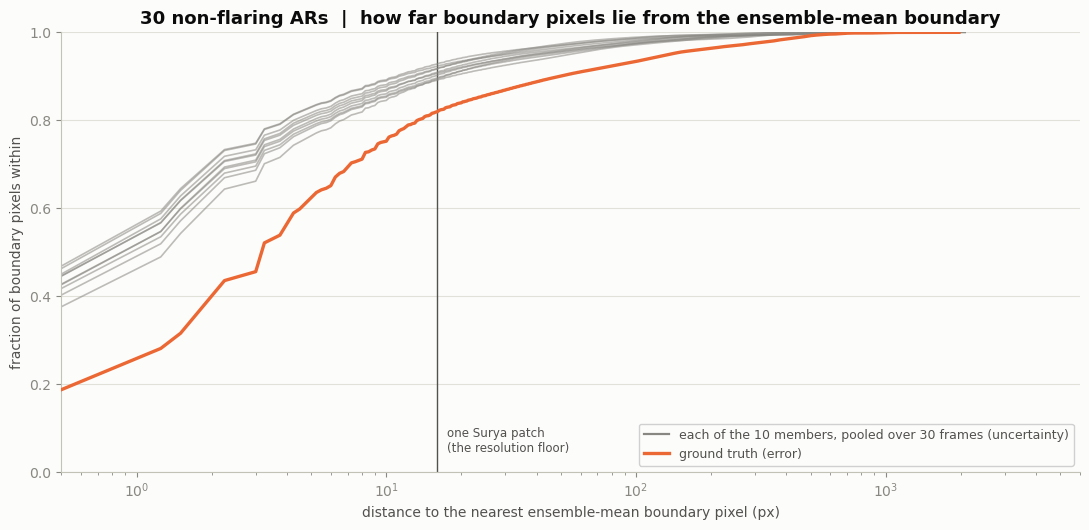

members (pooled)   within 1 patch (16 px):  90.8 %   within 2 patches:  94.5 %   median <=  1.25 px   n = 17,406,821
ground truth       within 1 patch (16 px):  81.9 %   within 2 patches:  87.3 %   median <=  3.25 px   n = 1,325,878

mean HD95 bounds the tail: 64 px for the members, 167 px for truth
  the old 672hr ensemble, same frames: 87 px and 166 px


In [10]:
def pooled_ecdf(df):
    "Summed counts -> (upper bin edge, cumulative fraction)."
    g = df.groupby("bin_hi", as_index=False)["count"].sum().sort_values("bin_hi")
    total = g["count"].sum()
    return g.bin_hi.values, np.cumsum(g["count"].values) / total, total


is_truth = dhist.series == "ground truth"
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.set_title(f"{NF} non-flaring ARs  |  how far boundary pixels lie from the "
             "ensemble-mean boundary", fontsize=13, fontweight="bold", color=ev.INK)

for member in MEMBERS:
    x, y_, _ = pooled_ecdf(dhist[dhist.series == member])
    ax.plot(x, y_, color=ev.MUTED, lw=1.2, alpha=0.55, zorder=2)
xt, yt, n_t = pooled_ecdf(dhist[is_truth])
ax.plot(xt, yt, color=ev.SERIES_2, lw=2.4, zorder=4)

ax.axvline(PATCH_PX, color=ev.INK_2, lw=1.0, zorder=1)
ax.annotate("one Surya patch\n(the resolution floor)", (PATCH_PX, 0.04), xytext=(7, 0),
            textcoords="offset points", fontsize=8.5, color=ev.INK_2, va="bottom")
ax.set_xscale("log")
ax.set_xlim(0.5, 6000)
ax.set_ylim(0, 1)
ax.set_xlabel("distance to the nearest ensemble-mean boundary pixel (px)")
ax.set_ylabel("fraction of boundary pixels within")
ev.recessive(ax)
ax.legend(handles=[
    plt.Line2D([], [], color=ev.MUTED, lw=1.6,
               label=f"each of the {N} members, pooled over {NF} frames (uncertainty)"),
    plt.Line2D([], [], color=ev.SERIES_2, lw=2.4, label="ground truth (error)")],
    loc="lower right", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
plt.tight_layout()
plt.show()


def within(df, limit):
    g = df.groupby("bin_hi", as_index=False)["count"].sum()
    return g.loc[g.bin_hi <= limit, "count"].sum() / g["count"].sum()


for label, sub in [("members (pooled)", dhist[~is_truth]), ("ground truth", dhist[is_truth])]:
    g = sub.groupby("bin_hi", as_index=False)["count"].sum().sort_values("bin_hi")
    tot = g["count"].sum()
    cum = np.cumsum(g["count"].values) / tot
    med = g.bin_hi.values[np.searchsorted(cum, 0.5)]
    print(f"{label:<18} within 1 patch ({PATCH_PX} px): {100 * within(sub, PATCH_PX):5.1f} %"
          f"   within 2 patches: {100 * within(sub, 2 * PATCH_PX):5.1f} %"
          f"   median <= {med:5.2f} px   n = {tot:,}")
print(f"\nmean HD95 bounds the tail: {frames.boundary_hd95_px.mean():.0f} px for the "
      f"members, {frames.boundary_error_hd95_px.mean():.0f} px for truth")
print(f"  the old 672hr ensemble, same frames: {base_frames.boundary_hd95_px.mean():.0f} px "
      f"and {base_frames.boundary_error_hd95_px.mean():.0f} px")

### Does the ratio track mask density?

The obvious confounder. HARP 11930's mask is 6x denser than the training-era validation set, and if
error-over-uncertainty simply grows with how much AR is in the frame, then the 2.07x was a statement
about *that frame's* density. The old run ruled this out ($\rho = -0.022$, p 0.91); the test is
repeated here because a different ensemble could have a different dependence.

Spearman rather than Pearson: the question is monotonicity, and both quantities have long-tailed
distributions across the cohort.

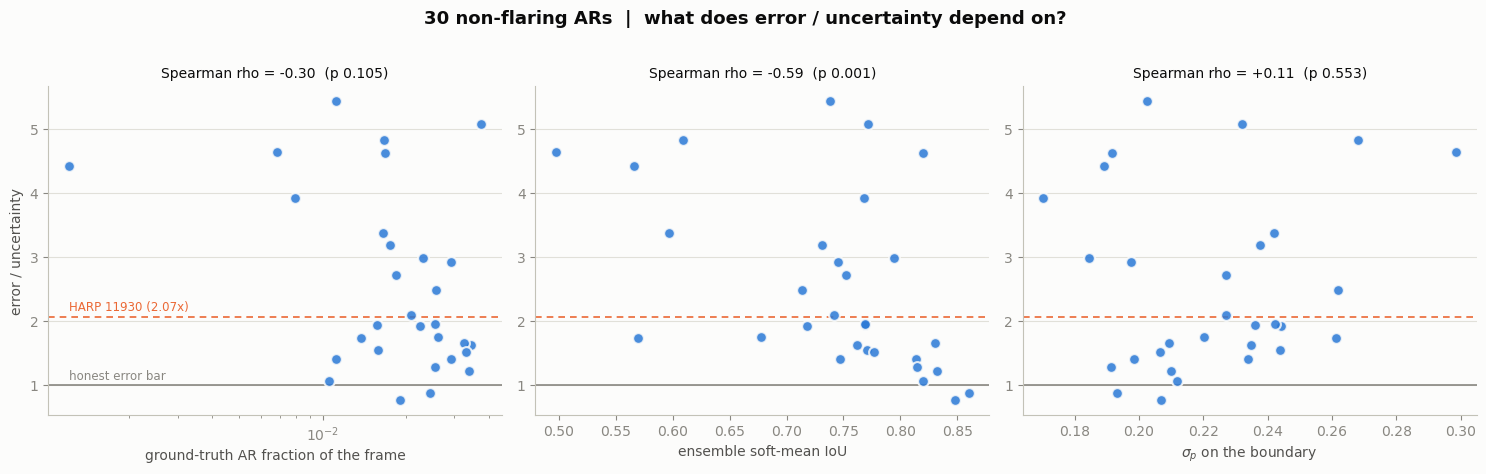

ratio vs truth AR fraction: Spearman rho -0.301 (p 0.105)
  -> no monotonic dependence on density in this band
  the old 672hr ensemble, same frames: rho -0.022 (p 0.906)

The cohort spans 0.00121 - 0.03749 in positive fraction (31x), so this is a real test over a real range,
not a comparison of two points. HARP 11930 sits at 0.03870.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
fig.suptitle(f"{NF} non-flaring ARs  |  what does error / uncertainty depend on?",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax, (col, xlabel, logx) in zip(axes, [
    ("truth_frac", "ground-truth AR fraction of the frame", True),
    ("soft_iou", "ensemble soft-mean IoU", False),
    ("boundary_sigma_prob", r"$\sigma_p$ on the boundary", False),
]):
    rho, p_s = stats.spearmanr(frames[col], frames.boundary_error_over_uncertainty)
    ax.scatter(frames[col], frames.boundary_error_over_uncertainty, s=60,
               color=ev.SERIES_1, alpha=0.85, zorder=3,
               edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
    ax.axhline(1.0, color=ev.MUTED, lw=1.2, zorder=1)
    ax.axhline(ref_ratio, color=ev.SERIES_2, lw=1.2, ls=(0, (4, 3)), zorder=2)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_title(f"Spearman rho = {rho:+.2f}  (p {p_s:.3f})", fontsize=10, color=ev.INK)
    ev.recessive(ax)
axes[0].set_ylabel("error / uncertainty")
axes[0].annotate("honest error bar", (frames.truth_frac.min(), 1.0), xytext=(0, 4),
                 textcoords="offset points", fontsize=8.5, color=ev.MUTED)
axes[0].annotate(f"HARP 11930 ({ref_ratio:.2f}x)", (frames.truth_frac.min(), ref_ratio),
                 xytext=(0, 4), textcoords="offset points", fontsize=8.5, color=ev.SERIES_2)
plt.tight_layout()
plt.show()

rho, p_s = stats.spearmanr(frames.truth_frac, frames.boundary_error_over_uncertainty)
print(f"ratio vs truth AR fraction: Spearman rho {rho:+.3f} (p {p_s:.3f})")
print(f"  -> {'density explains some of the ratio' if p_s < 0.05 else 'no monotonic dependence on density in this band'}")
print(f"  the old 672hr ensemble, same frames: rho "
      f"{stats.spearmanr(base_frames.truth_frac, base_frames.boundary_error_over_uncertainty)[0]:+.3f} "
      f"(p {stats.spearmanr(base_frames.truth_frac, base_frames.boundary_error_over_uncertainty)[1]:.3f})")
print(f"\nThe cohort spans {frames.truth_frac.min():.5f} - {frames.truth_frac.max():.5f} "
      f"in positive fraction ({frames.truth_frac.max() / frames.truth_frac.min():.0f}x), "
      f"so this is a real test over a real range,\nnot a comparison of two points. "
      f"HARP 11930 sits at {float(REF['truth_positive_fraction']):.5f}.")

## 3. §7 — Calibration, over 30 frames

Bin pixels by $\bar p$ and compare against the observed ground-truth frequency. On the diagonal is
perfect; **below is over-confident, above is under-confident**.

**A different axis from §2, and the two must not be merged.** §2 asked whether the member spread is
an honest error bar on the boundary's *position*. This asks whether the value $\bar p$ is an honest
frequency for a pixel's *class*. On HARP 11930 one was over-confident and the other
under-confident at the same time.

**Restricted to pixels where at least one member fired**, as in the single-frame notebook: the
$k = 0$ population is ~95 % of each frame and would set the curve's left end on its own. Its own AR
content is reported separately, because it is where the ensemble's misses hide.

The pooled curve sums the raw per-frame bin accumulators ($n$, $n_{\text{true}}$,
$\sum \bar p$), so it is the exact curve over all 30 frames' pixels — not an average of 30
per-frame curves, which would weight a sparse frame the same as a dense one.

`NOTES` records that `best.pth` tracks validation IoU, which for 9 of 10 members lands 2–3 epochs
*past* that member's own validation-loss optimum. Every member here is therefore selected at a
mildly overfit point, and the prediction is that the probabilities are worse calibrated than the
old run's early-stopped-by-collapse checkpoints even as the boundary gets better.

In [12]:
pooled = bins.groupby(["bin_lo", "bin_hi"], as_index=False)[["n", "n_true", "sum_p"]].sum()
pooled["mean_p"] = pooled.sum_p / pooled.n
pooled["observed"] = pooled.n_true / pooled.n
pooled["reliable"] = pooled.n >= MIN_N

show = pooled.assign(
    bin=lambda d: d.bin_lo.map("{:.1f}".format) + "-" + d.bin_hi.map("{:.1f}".format)
)[["bin", "n", "n_true", "mean_p", "observed", "reliable"]]
print(show.to_string(index=False, float_format=lambda x: f"{x:.4f}", na_rep="-"))

n_tot = int(pooled.n.sum())
mean_p = float(pooled.sum_p.sum() / n_tot)
observed = float(pooled.n_true.sum() / n_tot)
ok = pooled.reliable & pooled.n.gt(0)
w = pooled.n[ok] / pooled.n[ok].sum()
ece = float((w * (pooled.observed[ok] - pooled.mean_p[ok]).abs()).sum())

# Exact pooled Brier: the n-weighted mean of the per-frame Briers, each computed over that
# frame's own pixels. Equals the Brier over the union, which is why it is not re-derived
# from the bins (binning p would blur it).
brier_pooled = float((frames.brier * frames.n_binned).sum() / frames.n_binned.sum())
brier_old = float((base_frames.brier * base_frames.n_binned).sum() / base_frames.n_binned.sum())

# Murphy decomposition, on the binned approximation. reliability - resolution +
# uncertainty recovers the *binned* Brier; the gap against the exact figure above is the
# within-bin variation of p-bar that binning discards, and is reported rather than hidden.
o_bar = observed
unc_term = o_bar * (1 - o_bar)
rel_term = float((pooled.n * (pooled.mean_p - pooled.observed) ** 2).sum() / n_tot)
res_term = float((pooled.n * (pooled.observed - o_bar) ** 2).sum() / n_tot)

print(f"\npooled over {n_tot:,} pixels where >=1 member fired "
      f"({100 * n_tot / (NF * 4096 * 4096):.2f} % of the {NF} frames)")
print(f"  mean p-bar {mean_p:.4f}   observed AR frequency {observed:.4f}   "
      f"bias {mean_p - observed:+.4f}")
print(f"  Brier (exact, n-weighted over frames) {brier_pooled:.4f}")
print(f"  ECE, weighted |observed - p-bar| over reliable bins: {ece:.4f}")
print(f"\n  Murphy decomposition of the binned Brier:")
print(f"    reliability (lower better)  {rel_term:.4f}")
print(f"    resolution  (higher better) {res_term:.4f}")
print(f"    uncertainty (base rate)     {unc_term:.4f}")
print(f"    rel - res + unc             {rel_term - res_term + unc_term:.4f}  "
      f"vs exact {brier_pooled:.4f}  "
      f"(gap {abs(rel_term - res_term + unc_term - brier_pooled):.4f} = within-bin spread)")
# The old run's pooled figures, from its own bin accumulators -- pooled against pooled.
# base_frames.bias.mean() is a *different* quantity (every AR weighted equally regardless
# of how many pixels it contributes) and is reported in the paired table below instead.
base_pooled = base_bins.groupby(["bin_lo", "bin_hi"], as_index=False)[
    ["n", "n_true", "sum_p"]].sum()
n_tot_o = int(base_pooled.n.sum())
mean_p_o = float(base_pooled.sum_p.sum() / n_tot_o)
observed_o = float(base_pooled.n_true.sum() / n_tot_o)
ok_o = base_pooled.n >= MIN_N
w_o = base_pooled.n[ok_o] / base_pooled.n[ok_o].sum()
ece_o = float((w_o * (base_pooled.n_true[ok_o] / base_pooled.n[ok_o]
                      - base_pooled.sum_p[ok_o] / base_pooled.n[ok_o]).abs()).sum())
rel_o = float((base_pooled.n * (base_pooled.sum_p / base_pooled.n
                                - base_pooled.n_true / base_pooled.n) ** 2).sum() / n_tot_o)

print(f"\n  old 672hr ensemble, same 30 ARs, pooled over {n_tot_o:,} px:")
print(f"    mean p-bar {mean_p_o:.4f}   observed {observed_o:.4f}   "
      f"bias {mean_p_o - observed_o:+.4f}")
print(f"    Brier {brier_old:.4f}   ECE {ece_o:.4f}   reliability {rel_o:.4f}")
print(f"  HARP 11930 single frame:         Brier {REF_BRIER:.4f}  bias {REF_BIAS:+.4f}")
thin = pooled.index[~pooled.reliable & pooled.n.gt(0)].tolist()
print(f"\n  pooled bins below the {MIN_N:,}-pixel floor: "
      + (f"{thin}" if thin else "none; every non-empty bin is a real measurement"))

print(f"\n--- what hides in k = 0 ---")
print(f"  excluded pixels: {int(frames.n_quiet.sum()):,} "
      f"({100 * frames.quiet_frac.mean():.2f} % of a frame on average)")
print(f"  their ground-truth AR frequency: "
      f"{describe(frames.quiet_true_frac, '{:.5f}')}")
print(f"  true AR pixels no member found:  "
      f"{describe(100 * frames.missed_ar_frac, '{:.1f}')} % of each frame's AR")
print(f"  (old 672hr: {base_frames.missed_ar_frac.mean() * 100:.1f} %; HARP 11930: 7.7 %)")

    bin       n  n_true  mean_p  observed  reliable
0.0-0.1  234966   18700  0.0816    0.0796      True
0.1-0.2  687423  121463  0.1488    0.1767      True
0.2-0.3  733317  233618  0.2519    0.3186      True
0.3-0.4  834764  316209  0.3501    0.3788      True
0.4-0.5  794538  371522  0.4497    0.4676      True
0.5-0.6  768058  432881  0.5489    0.5636      True
0.6-0.7  724583  480622  0.6505    0.6633      True
0.7-0.8  829296  632146  0.7514    0.7623      True
0.8-0.9 1142609  957314  0.8540    0.8378      True
0.9-1.0 6381753 6240236  0.9820    0.9778      True

pooled over 13,131,307 pixels where >=1 member fired (2.61 % of the 30 frames)
  mean p-bar 0.7398   observed AR frequency 0.7467   bias -0.0069
  Brier (exact, n-weighted over frames) 0.1112
  ECE, weighted |observed - p-bar| over reliable bins: 0.0138

  Murphy decomposition of the binned Brier:
    reliability (lower better)  0.0004
    resolution  (higher better) 0.0776
    uncertainty (base rate)     0.1892
    rel - r

### Is the direction of the miscalibration consistent, and did it move?

The pooled curve can hide cancelling frames. If the sign of the bias is the same on nearly every
AR, under-confidence is a property of the ensemble. If it is mixed, the pooled number is an average
of two different behaviours.

The paired rows then ask whether the stabilization moved calibration, in either direction. This is
the test of the `NOTES` hypothesis directly: selecting on IoU lands past the calibration optimum,
so the stable members' probabilities could be *worse* even where their boundaries are better.

In [13]:
print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("Brier (per frame)", "brier", "{:.4f}"),
    ("bias (p-bar - observed)", "bias", "{:+.4f}"),
    ("ECE", "ece", "{:.4f}"),
    ("mean p-bar where >=1 fired", "mean_p", "{:.4f}"),
    ("observed AR freq where >=1 fired", "observed", "{:.4f}"),
]:
    print(f"{label:<34}{describe(frames[col], fmt)}")

n_under = int((frames.bias < 0).sum())
n_over_c = int((frames.bias > 0).sum())
print(f"\n  under-confident (bias < 0, observed exceeds p-bar): {n_under}/{NF}")
print(f"  over-confident  (bias > 0):                        {n_over_c}/{NF}")
w_bias = stats.wilcoxon(frames.bias)
print(f"\n  Wilcoxon signed-rank on the {NF} biases vs 0: p = {w_bias.pvalue:.2e}")
print(f"  -> the sign is {'consistent across the cohort' if w_bias.pvalue < 0.05 else 'not consistent'}; "
      f"the old 672hr run was under-confident on "
      f"{int((base_frames.bias < 0).sum())}/{NF} and HARP 11930 at {REF_BIAS:+.4f}")
print(f"\n  Spearman, bias vs truth AR fraction: "
      f"rho {stats.spearmanr(frames.truth_frac, frames.bias)[0]:+.3f} "
      f"(p {stats.spearmanr(frames.truth_frac, frames.bias)[1]:.3f})")

print(f"\n--- paired against the old 672hr ensemble, per AR ---")
print(f"{'':<30}{'stable':>10}{'672hr':>10}{'mean d':>11}{'median d':>11}"
      f"{'n up':>8}{'Wilcoxon':>12}")
print("-" * 98)
for label, col, fmt, hib in [
    ("Brier (lower better)", "brier", "{:.4f}", False),
    ("bias (0 is calibrated)", "bias", "{:+.4f}", None),
    ("|bias| (lower better)", "abs_bias", "{:.4f}", False),
    ("ECE (lower better)", "ece", "{:.4f}", False),
    ("mean p-bar", "mean_p", "{:.4f}", None),
    ("missed AR fraction", "missed_ar_frac", "{:.4f}", False),
]:
    if col == "abs_bias":
        pair["abs_bias"] = pair.bias.abs()
        pair["abs_bias_old"] = pair.bias_old.abs()
    print(f"{label:<30}{paired(col, fmt, hib)}")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Brier (per frame)                 0.1168 +/- 0.0355   median 0.1069   [0.0699, 0.2035]
bias (p-bar - observed)           +0.0021 +/- +0.0622   median -0.0062   [-0.0679, +0.2648]
ECE                               0.0585 +/- 0.0436   median 0.0488   [0.0272, 0.2651]
mean p-bar where >=1 fired        0.7316 +/- 0.0789   median 0.7292   [0.4739, 0.8472]
observed AR freq where >=1 fired  0.7295 +/- 0.1083   median 0.7551   [0.4197, 0.8787]

  under-confident (bias < 0, observed exceeds p-bar): 17/30
  over-confident  (bias > 0):                        13/30

  Wilcoxon signed-rank on the 30 biases vs 0: p = 5.16e-01
  -> the sign is not consistent; the old 672hr run was under-confident on 23/30 and HARP 11930 at -0.0603

  Spearman, bias vs truth AR fraction: rho -0.215 (p 0.254)

--- paired against the old 672hr ensemble, per AR ---
     

### The pooled reliability curve

The 30 per-frame curves sit behind the pooled one in grey, so the spread is visible rather than
averaged away. The old ensemble's pooled curve is drawn as a dashed orange line for comparison —
two series, both frequencies on the same 0–1 axes, so they share a panel legitimately.

Bin counts are in the lower panel on a log scale, **not** a second y-axis: a bin holding $10^3$
pixels and one holding $10^7$ must not be drawn as equals, and two scales on one plot would invent
a relationship between frequency and count that is not there.

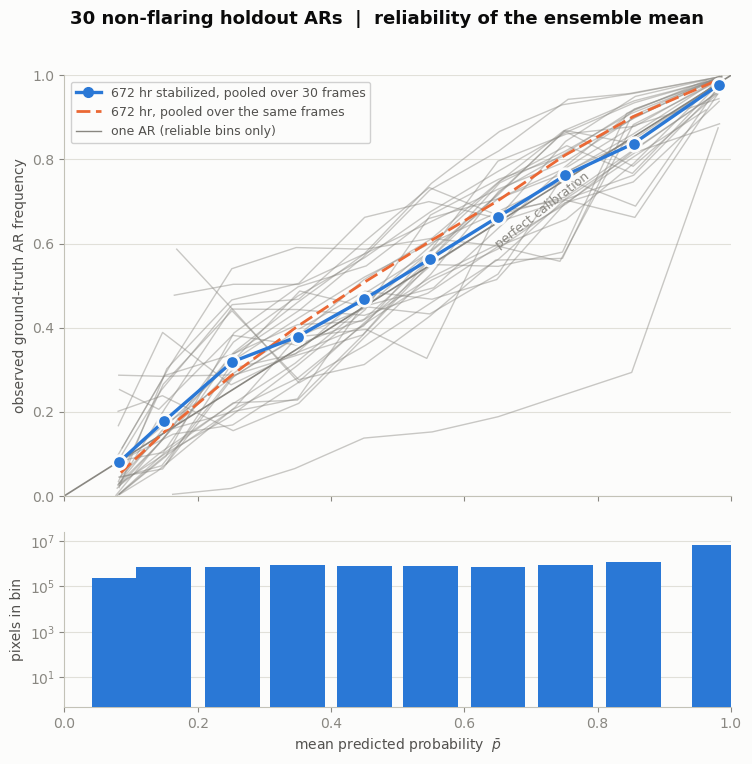

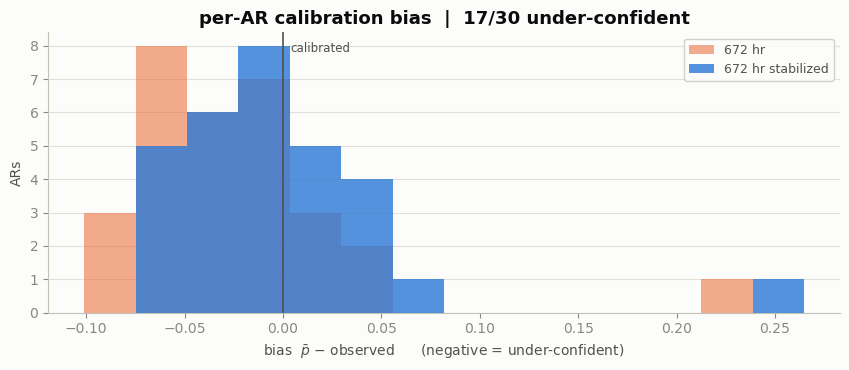

In [14]:
fig, (ax, axc) = plt.subplots(2, 1, figsize=(8.6, 8.2), sharex=True,
                              gridspec_kw={"height_ratios": [2.4, 1], "hspace": 0.12})
fig.suptitle(f"{NF} non-flaring holdout ARs  |  reliability of the ensemble mean",
             fontsize=13, fontweight="bold", color=ev.INK, y=0.96)

ax.plot([0, 1], [0, 1], color=ev.MUTED, lw=1.2, zorder=2)
ax.annotate("perfect calibration", (0.72, 0.72), xytext=(0, -14),
            textcoords="offset points", ha="center", fontsize=9, color=ev.MUTED,
            rotation=38, rotation_mode="anchor")

# Per-frame curves first, restricted to each frame's own reliable bins.
for frame, g in bins.groupby("frame"):
    g = g[g.n >= MIN_N]
    if len(g) > 1:
        ax.plot(g.sum_p / g.n, g.n_true / g.n, color=ev.MUTED, lw=1.0, alpha=0.45, zorder=3)

# The old ensemble's pooled curve, from the accumulators §3 already summed.
base_ok = base_pooled.n >= MIN_N
ax.plot(base_pooled.sum_p[base_ok] / base_pooled.n[base_ok],
        base_pooled.n_true[base_ok] / base_pooled.n[base_ok],
        color=ev.SERIES_2, lw=2.0, ls=(0, (5, 2)), zorder=4)

ax.plot(pooled.mean_p[ok], pooled.observed[ok], color=ev.SERIES_1, lw=2.4, zorder=5)
ax.scatter(pooled.mean_p[ok], pooled.observed[ok], s=95, color=ev.SERIES_1, zorder=6,
           edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
thin_mask = (~pooled.reliable) & pooled.n.gt(0)
if thin_mask.any():
    ax.scatter(pooled.mean_p[thin_mask], pooled.observed[thin_mask], s=95,
               facecolors="none", edgecolors=ev.SERIES_1, linewidths=2, zorder=6)
ax.set_ylabel("observed ground-truth AR frequency")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(handles=[
    plt.Line2D([], [], color=ev.SERIES_1, lw=2.4, marker="o", ms=7,
               label=f"672 hr stabilized, pooled over {NF} frames"),
    plt.Line2D([], [], color=ev.SERIES_2, lw=2.0, ls=(0, (5, 2)),
               label="672 hr, pooled over the same frames"),
    plt.Line2D([], [], color=ev.MUTED, lw=1.0, label="one AR (reliable bins only)")],
    loc="upper left", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ev.recessive(ax)

axc.set_yscale("log")
nonempty = pooled.n > 0
axc.bar(pooled.mean_p[nonempty], pooled.n[nonempty], width=0.082, color=ev.SERIES_1,
        bottom=0.5, zorder=3)
axc.set_ylim(0.5, float(pooled.n.max()) * 4)
if thin_mask.any():
    axc.axhline(MIN_N, color=ev.MUTED, lw=1.0, zorder=4)
    axc.annotate(f"{MIN_N:,} px reliability floor", (0.02, MIN_N), xytext=(0, 5),
                 textcoords="offset points", fontsize=8.5, color=ev.MUTED, zorder=5)
axc.set_xlabel(r"mean predicted probability  $\bar p$")
axc.set_ylabel("pixels in bin")
ev.recessive(axc)
plt.show()

fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.set_title(f"per-AR calibration bias  |  {n_under}/{NF} under-confident",
             fontsize=13, fontweight="bold", color=ev.INK)
lo = min(frames.bias.min(), base_frames.bias.min())
hi = max(frames.bias.max(), base_frames.bias.max())
edges = np.linspace(lo, hi, 15)
ax.hist(base_frames.bias, bins=edges, color=ev.SERIES_2, alpha=0.55, zorder=2,
        label="672 hr")
ax.hist(frames.bias, bins=edges, color=ev.SERIES_1, alpha=0.8, zorder=3,
        label="672 hr stabilized")
ax.axvline(0, color=ev.INK_2, lw=1.2, zorder=4)
ax.annotate("calibrated", (0, ax.get_ylim()[1] * 0.93), xytext=(5, 0),
            textcoords="offset points", fontsize=8.5, color=ev.INK_2)
ax.set_xlabel(r"bias  $\bar p$ − observed      (negative = under-confident)")
ax.set_ylabel("ARs")
ax.legend(loc="upper right", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ev.recessive(ax)
plt.tight_layout()
plt.show()

## 4. Three exemplars

The aggregate needs something concrete under it. The AR with the **lowest**, the **median** and the
**highest** error-over-uncertainty, each with the $\sigma_r$ map on its own most-contested window —
the same panel §6 of the single-frame notebook draws.

$\sigma_r$ is recomputed here from the cached $\bar p$ and $\sigma_p$ rather than stored: it costs a
second and would have added 67 MB per frame to the cache.

Drawn only on the transition band $0.1 < \bar p < 0.9$. Outside it the ratio
$\sigma_p / |\nabla \bar p|$ divides a near-zero numerator by a near-zero denominator — numerical
noise with no boundary to be the uncertainty *of*. Values are clipped at one patch rather than
rescaled, so the colour means the same thing on all three panels.

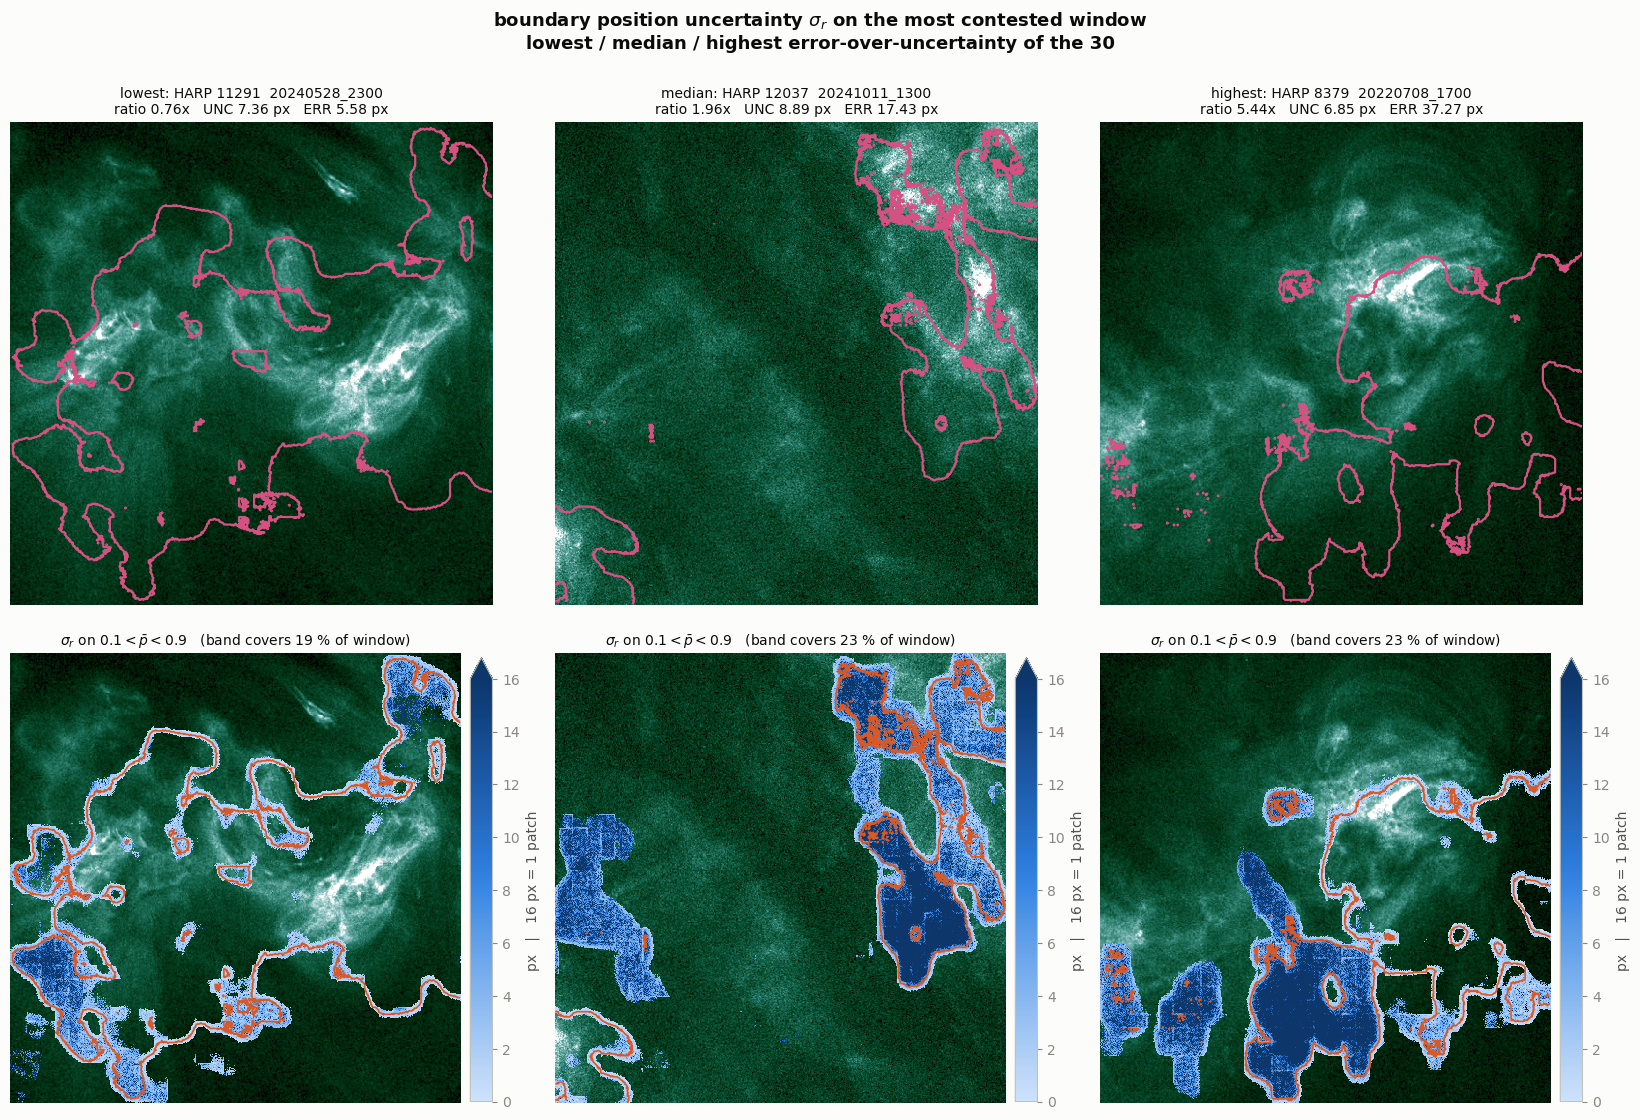

             HARP           frame   ratio   UNC px   ERR px     IoU  truth frac   Brier     bias  ratio old
lowest      11291   20240528_2300    0.76     7.36     5.58  0.8479     0.01901  0.0699  -0.0601       0.78
median      12037   20241011_1300    1.96     8.89    17.43  0.7692     0.02545  0.1032  -0.0339       1.64
highest      8379   20220708_1700    5.44     6.85    37.27  0.7383     0.01121  0.1192  +0.0125       2.23


In [15]:
ordered = frames.sort_values("boundary_error_over_uncertainty").reset_index(drop=True)
picks = [("lowest", ordered.iloc[0]), ("median", ordered.iloc[NF // 2]),
         ("highest", ordered.iloc[-1])]


def load_channel(frame_dir, channel):
    "One channel in display units: undoes the standardization only, as infer_file does."
    with xr.open_dataset(os.path.join(frame_dir, "channels.nc"), engine="h5netcdf") as ds:
        normalized = ds[channel].values.astype(np.float32)
    s = scalers[channel]
    return normalized * (s["std"] + s["epsilon"]) + s["mean"]


fig, axes = plt.subplots(2, 3, figsize=(16.5, 11.4))
fig.suptitle(r"boundary position uncertainty $\sigma_r$ on the most contested window"
             "\nlowest / median / highest error-over-uncertainty of the 30",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

for col, (tag, row) in enumerate(picks):
    frame_dir = os.path.join(INFER_ROOT, row.frame)
    with xr.open_dataset(os.path.join(frame_dir, "ensemble_mean.nc"),
                         engine="h5netcdf") as ds:
        p_mean = ds.ar_probability_mean.values
        p_sd = ds.ar_probability_sd.values
    gy, gx = np.gradient(p_mean)
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_r = (p_sd / np.hypot(gy, gx)).astype(np.float32)
    del gy, gx

    y0, x0, y1, x1 = int(row.win_y0), int(row.win_x0), int(row.win_y1), int(row.win_x1)
    img = load_channel(frame_dir, CHANNEL)[y0:y1, x0:x1]
    vmin, vmax = ev.channel_clim(CHANNEL, img)
    sub_soft = (p_mean > 0.5)[y0:y1, x0:x1]
    sub_pm = p_mean[y0:y1, x0:x1]
    sub_sigma = sigma_r[y0:y1, x0:x1]
    band = (sub_pm > 0.1) & (sub_pm < 0.9) & np.isfinite(sub_sigma)
    del p_mean, p_sd, sigma_r

    for r_ in (0, 1):
        axes[r_, col].imshow(img, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
                             interpolation="nearest")
        axes[r_, col].axis("off")

    axes[0, col].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.MASK_FILL],
                         linewidths=1.6)
    axes[0, col].set_title(
        f"{tag}: HARP {int(row.harpnum)}  {row.frame}\n"
        f"ratio {row.boundary_error_over_uncertainty:.2f}x   "
        f"UNC {row.boundary_assd_px:.2f} px   ERR {row.boundary_error_assd_px:.2f} px",
        fontsize=10, color=ev.INK)

    im = axes[1, col].imshow(np.ma.masked_where(~band, sub_sigma), cmap=ev.SEQ,
                             vmin=0, vmax=PATCH_PX, interpolation="nearest")
    axes[1, col].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.CONTOUR[0.5]],
                         linewidths=1.2)
    axes[1, col].set_title(
        r"$\sigma_r$ on $0.1 < \bar p < 0.9$"
        f"   (band covers {100 * band.mean():.0f} % of window)",
        fontsize=10, color=ev.INK)
    cb = fig.colorbar(im, ax=axes[1, col], fraction=0.046, pad=0.02, extend="max")
    cb.set_label(f"px   |   {PATCH_PX} px = 1 patch", color=ev.INK_2)

plt.tight_layout()
plt.show()

print(f"{'':<10}{'HARP':>7}{'frame':>16}{'ratio':>8}{'UNC px':>9}{'ERR px':>9}"
      f"{'IoU':>8}{'truth frac':>12}{'Brier':>8}{'bias':>9}{'ratio old':>11}")
for tag, row in picks:
    old = pair.loc[pair.harpnum == row.harpnum,
                   "boundary_error_over_uncertainty_old"].iloc[0]
    print(f"{tag:<10}{int(row.harpnum):>7}{row.frame:>16}"
          f"{row.boundary_error_over_uncertainty:>8.2f}{row.boundary_assd_px:>9.2f}"
          f"{row.boundary_error_assd_px:>9.2f}{row.soft_iou:>8.4f}"
          f"{row.truth_frac:>12.5f}{row.brier:>8.4f}{row.bias:>+9.4f}{old:>11.2f}")

## What this cohort says

**1. The caveat is resolved: the 2.28x was not an artifact of collapsed members.** The stabilized
ensemble gives **2.55 ± 1.39** (median 1.95, range 0.76–5.44) against the old **2.28 ± 1.31**, and
the paired test says that difference is nothing — median per-AR change **−0.01**, Wilcoxon
**p = 0.58**, 15 of 30 ARs improved and 15 did not. 28 of 30 frames still have error exceeding
uncertainty and 14 of 30 still exceed 2x. Fixing the optimizer removed every collapsed checkpoint
and did **not** make the bootstrap spread an honest error bar. Member scatter remains a lower bound
on boundary error, roughly half of it.

**2. The uncertainty got tighter; the error did not. That is the wrong direction.** UNC fell
13.97 → 9.73 px and ERR only 24.96 → 24.32 px, so the *cohort-level* ratio mean-ERR / mean-UNC rose
**1.79x → 2.50x**. Neither paired difference is significant on its own (UNC p 0.10, ERR p 0.080),
and the reason is that the UNC drop is almost entirely tail: the median per-AR ΔUNC is
**−0.40 px**, while **4 of 300** member-frames in the old run sat above 100 px (max 434.8) and
**0 of 300** do here (max 97.9). Removing detection failures shrank the mean spread by 30 % without
moving the typical frame — and a narrower spread around an unchanged error is a *worse* error bar,
not a better one. $\sigma_p$ on the boundary tells the same story: 0.2376 → 0.2225, down on 25 of
30 ARs (p 4.4e-05).

**3. IoU improved decisively and boundary localization did not follow.** Soft-mean IoU
0.7115 → **0.7407**, up on **29 of 30** ARs (p 2.6e-07), driven entirely by recall
(+0.0401, 29/30, p 3.7e-09) with precision slightly *down* (−0.0065, p 0.070) — the over-
segmentation `NOTES` flagged at training time, now visible on holdout. Yet ERR is unmoved and error
HD95 is identical to three significant figures (166.5 → 166.6 px). Four percent more of the true AR
pixels get found without the boundary being better located. **Pixel overlap and boundary position
are different axes, and the 4x-data gain landed on the first one only.**

**4. The ICC is 0.187 against 0.192 — and that falsifies the `NOTES` prediction.** `NOTES` read the
old 0.192 as "driven by the heavy tail of those three members, not by uniform scatter", which
predicts a *higher* ICC once they are gone. Both variance components fell by about 3.5x
($\sigma_{between}$ 16.51 → 4.62 px, $\sigma_{within}$ 33.91 → 9.65 px) and their ratio did not
budge. The **81 % members / 19 % frame identity** split is a genuine property of bootstrapping this
model, not a signature of broken checkpoints.

**5. Per-frame member ranking is now close to noise — but replicate identity transfers.** Kendall's
$W$ collapses **0.331 → 0.104** (still non-random, Friedman p 8.9e-04): the old run's concordance
was mostly three bad checkpoints being reliably bad. boot07 is again the tightest member overall
(6.10 px) and again its own frame's tightest on only **6/30**; boot08 went from loosest in the old
run (31.24 px) to sixth here (9.66 px) as its validation IoU rose 0.518 → 0.597. The new result is
the paired column: across the ten replicates, mean ASSD old vs new correlates at Spearman
**+0.733 (p 0.016)** — a replicate that yielded a loose member yields a loose one again when
retrained under a different optimizer schedule. **Which bootstrap draw you got transfers; which
frame you are looking at does not.**

**6. Method A is partly rehabilitated, and the old notebook's diagnosis is now supported rather
than asserted.** A vs B goes from $r$ = 0.053 (p 0.78) to **$r$ = 0.386 (p 0.035)**, agreement
within 20 % from 4/30 to 7/30, and A's low bias from −35 % to **−27 %**. The old notebook explained
A's failure as a local linearization blind to detached islands and regions the ensemble missed;
removing the detection failures is exactly the intervention that prediction calls for, and the
correlation became significant. A still is not a substitute for B — two thirds of frames disagree
by more than 20 % and A reads systematically low — but it is no longer unrelated. A's own two
assumptions hold on all 30 frames (within-patch range 0.692 ± 0.042, never flat; seam bias
1.33 ± 0.05x).

**7. §7: the predicted probability saturation happened, and it helped — because it cancelled a
pre-existing under-confidence.** Mean $\bar p$ rose on **30 of 30** ARs, +0.0546 (p 1.9e-09),
exactly what `NOTES` predicted for `best.pth` checkpoints sitting 2–3 epochs past their own
validation-loss optimum. But the old ensemble was *under*-confident, so that extra confidence moved
it onto the diagonal: pooled bias **−0.0311 → −0.0069**, pooled ECE **0.0317 → 0.0138**, Murphy
reliability **0.0015 → 0.0004**, and per-AR Brier 0.1230 → 0.1168 (p 0.003, worse on only 7/30).
Two things keep that from being a clean win. The per-AR |bias| and ECE improvements are **not**
significant (p 0.16, p 0.37), and **the sign consistency is gone**: 17 under / 13 over-confident
with Wilcoxon p 0.52, against 23/30 under at p 1.5e-3 before. **So the old notebook's
recommendation to threshold below 0.5 no longer holds** — it was correcting an under-confidence
that is no longer there, and there is now no consistent direction to correct.

**8. One frame does much of the calibration damage, and it is a near-empty mask.**
`20200607_0100` (HARP 7419) has a truth positive fraction of **0.0012** — 0.19x the training-era
rate, 17x sparser than the cohort median — and carries the worst bias (+0.2648), Brier (0.2035) and
ECE (0.2651) of the 30. It is the one frame where the ground truth is nearly empty while the
ensemble still calls 1.0 % of the disk an AR. Read the medians in §3, not the means, for that
reason.

**9. The density confounder is still ruled out, less emphatically.** ERR/UNC against truth positive
fraction gives Spearman $\rho = -0.301$ (p 0.105) over the same **31x** density range, against the
old −0.022 (p 0.91). Not significant at $n = 30$, so the conclusion stands — HARP 11930's 2.07x was
not an artifact of its dense mask — but the point estimate is no longer near zero, and its sign says
*denser* frames have *lower* ratios, the opposite of the confounder originally feared.

**10. Absolute scale, unchanged in the way that matters.** UNC 5.84″ ≈ 4,229 km and ERR 14.59″ ≈
10,606 km against one Surya patch = 9.6″ ≈ 6,968 km, so the typical error is about **1.5 patches** —
still past the model's own resolution floor. Pooled over 17.4 M member distances and 1.33 M truth
distances, **90.8 %** of member boundary pixels lie within one patch against **81.9 %** for truth.
The $k = 0$ population still hides **6.3 ± 2.0 %** of each frame's true AR (old run 6.8 %, paired
p 0.011) across 490 M excluded pixels averaging 97.4 % of a frame; no threshold reaches those.

### The one-line version

Stabilizing the optimizer bought a better ensemble (+0.029 IoU, no collapsed members, a 4.4x
smaller worst-case member deviation) and a *worse-behaved* error bar (spread down 30 %, error flat).
Of the five results the old cohort reported, **three survive unchanged** (ratio ~2.3–2.6x, ICC
~0.19, density ruled out), **one reverses** (consistent under-confidence becomes no consistent
direction), and **one is partly rehabilitated** (Method A correlates with B again). None of the
survivors can be blamed on collapsed checkpoints any more.

### What still limits all of it

- **The truth masks are whole-disk** (assumption 2 at the top). "Non-flaring" describes each
  catalog's *target* AR, not the frame, so some of the 24.32 px ERR is boundary error on
  neighbouring regions that may not be quiescent. A per-HARP-restricted mask is the clean fix and
  is not done here.
- **One seed.** All ten members share it, so the spread omits the optimization-path variance
  entirely — an independent second reason it understates error, and the one thing *neither*
  ensemble can see. `configs_bootstrap/672hr_stable_seed/` is generated to size it.
- **IoU-selected checkpoints.** Point 7 is a story about selection, and the direct test is to
  re-run this cohort at each member's min-validation-loss epoch
  (`672hr_stable_minloss_infer_holdout_nonflaring30`, the epochs listed in `NOTES`). Every
  `epoch_N.pth` is retained, so that needs no retraining.
- **HARP 11930 has not been re-run under `672hr_stable`.** Every reference marker in the figures
  above is an old-regime number, and §2's comparison against it is cross-regime. The 30-AR paired
  baseline is the one that is apples-to-apples.
- **One timestep per AR.**